In [1]:
import json, time
import numpy as np, h5py, pandas as pd
import matplotlib.pyplot as plt
from mem import analysis as A, config as cfg, validation as V

EVENTS = "data/events.h5"              # test subsample: "data/events_s40.h5"
PDF = "NNPDF40"                        # key of cfg.PDF_SETS; the binned results (paper) always use cfg.PDF_GEN = NNPDF23
LUMI0 = 500.0                          # fb^-1, luminosity of the paper's fits
LUMIS = np.array([300, 500, 1000, 1500, 2000, 2500, 3000.0])
PT_BINS = np.arange(500, 3501, 100)    # paper binning (Eq. 5.13)
HYPS = ["Scalar", "VLF", "Zp01", "Zp20"]
TRUTHS = ["Scalar", "VLF", "Zp20", "Zp01"]
LABEL = {"Scalar": "Scalar", "VLF": "VLF", "Zp01": "$Z'$ narrow", "Zp20": "$Z'$ broad", "SM": "SM"}
pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

S = A.Sample(EVENTS, pdf=PDF)                                       # unbinned analysis
S23 = S if PDF == cfg.PDF_GEN else A.Sample(EVENTS, pdf=cfg.PDF_GEN)  # binned analysis / paper comparisons
with h5py.File(EVENTS) as h:
    chan = h["channel"][:]
    w_lhe = h["w_lhe"][:]
    alphas0 = h["alphas0"][:]
    nvec = h["n"][:]
print(f"PDF = {PDF} ({S.pdf_info['set']}): {len(S.w)} events, sigma = {S.sigma:.5f} pb, N_eff = {S.n_eff:.0f}")

PDF = NNPDF40 (NNPDF40_nlo_as_01180): 2405721 events, sigma = 1.38515 pb, N_eff = 520841


In [2]:
# Published results (arXiv:2611.08459): Tables 2-4 (L = 500 fb^-1) and Fig. 12 (L = 3 ab^-1).
# theta = y_DM^2 (Scalar, VLF) or g_q g_t (Z').
PAPER_FITS = {
    "Scalar": {"Scalar": (1510.2, 7.6**2, 0.009), "VLF": (1744.5, 4.6**2, 0.85),
               "Zp01": (2500.1, -0.016*0.35, 23.3), "Zp20": (2882.0, -0.030*1.58, 10.5)},
    "VLF":    {"VLF": (1505.3, 3.8**2, 0.008), "Scalar": (1247.0, 5.9**2, 0.83),
               "Zp01": (2908.9, -0.019*0.35, 22.2), "Zp20": (2811.0, -0.028*1.58, 9.3)},
    "Zp20":   {"Zp20": (3009.8, -0.034*1.58, 0.06), "Zp01": (2915.9, -0.023*0.35, 11.0),
               "VLF": (1518.0, 3.6**2, 11.2), "Scalar": (1336.1, 6.0**2, 10.3)},
}
PAPER_YIELD = {"Scalar": ("Scalar", 1510.2, 7.6**2, 3032), "VLF": ("VLF", 1505.3, 3.8**2, 3465),
               "Zp20": ("Zp20", 3009.8, -0.034*1.58, 1372)}       # signal events in 0.5 < pT < 3.5 TeV, 500 fb^-1
PAPER_Z3000 = {  # [H0][H1]
    "Scalar": {"VLF": 2.2, "Zp01": 12.5, "Zp20": 7.8}, "VLF": {"Scalar": 2.2, "Zp01": 12.4, "Zp20": 8.2},
    "Zp01": {"Scalar": 11.7, "VLF": 11.5, "Zp20": 8.0}, "Zp20": {"Scalar": 7.9, "VLF": 7.5, "Zp01": 9.4}}

## Sample and weight normalisation

The SM sample is a fixed-order aMC@NLO run (`[QCD NP]` at $y_{\rm DM}=0$, i.e. the LO Born) with an $m_{t\bar t}$ bias, signed NNPDF2.3 PDFs, and $\mu_R=\mu_F=H_T/2$.



In [3]:
norm = S.meta["norm"]
print(json.dumps({k: norm[k] for k in ("sigma_summary", "sigma_lo", "sigma_lo_err", "kappa")}, indent=1))
print(f"sigma_LO total = {sum(norm['sigma_lo'].values()):.5f} pb   vs summary.txt {norm['sigma_summary']} pb")
Sg = A.Sample(EVENTS, flux_mode="signed")      # generator weights (signed NNPDF23, identity conversion)
Ss = Sg if PDF == cfg.PDF_GEN else A.Sample(EVENTS, pdf=PDF, flux_mode="signed")
print(f"generator (signed PDFs): negative-weight events {np.mean(Sg.w < 0):.2%}, share of sigma "
      f"{Sg.w[Sg.w < 0].sum() / Sg.sigma:.1e}, median max(x1,x2) {np.median(np.maximum(Sg.x1, Sg.x2)[Sg.w < 0]):.2f}")
print(f"nominal ({PDF}, clipped PDFs, f -> max(f, 0)): {S.n_dropped} events removed ({S.n_dropped / len(Ss.w):.2%}), "
      f"sigma = {S.sigma:.5f} pb (signed {Ss.sigma:.5f}), min weight {S.w.min():.1e}, "
      f"r_T(Scalar) in [{S.r_benchmark('Scalar').min():.3f}, {S.r_benchmark('Scalar').max():.3f}] "
      f"(signed: up to {Ss.r_benchmark('Scalar').max():.3g})")

{
 "sigma_summary": 1.424,
 "sigma_lo": {
  "gg": 0.9764899359011249,
  "qq": 0.4496284719499506
 },
 "sigma_lo_err": {
  "gg": 0.0007406363048525443,
  "qq": 0.0002680426337974907
 },
 "kappa": {
  "gg": 9.778483997386129,
  "qq": 8.901427430475005
 }
}
sigma_LO total = 1.42612 pb   vs summary.txt 1.424 pb


generator (signed PDFs): negative-weight events 2.22%, share of sigma -4.2e-04, median max(x1,x2) 0.76


nominal (NNPDF40, clipped PDFs, f -> max(f, 0)): 17 events removed (0.00%), sigma = 1.38515 pb (signed 1.38515), min weight 2.5e-34, r_T(Scalar) in [0.784, 1.166] (signed: up to 1.17)


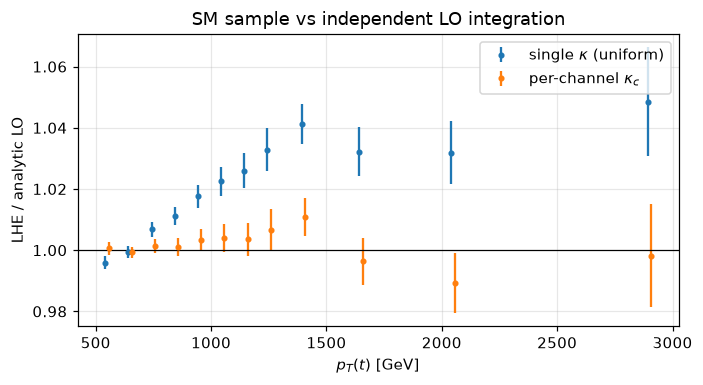

In [4]:
# Independent LO integration (cached): shape test of the two normalisations against it
import os
bins = np.array([500, 600, 700, 800, 900, 1000, 1100, 1200, 1300, 1500, 1800, 2300, 3500.])
cache = "data/lo_integration_pt.npz"   # LO histogram, 16M points, NO m_tt ceiling (must match the generation cuts)
c = np.load(cache) if os.path.exists(cache) else None
if c is None or len(c["bins"]) != len(bins) or not np.allclose(c["bins"], bins):
    lo = V.lo_integration(16_000_000, seed=7)        # about 2 min
    np.savez(cache, *V.hist_with_err(lo["pt"], lo["w"], bins), bins=bins)
    c = np.load(cache)
h_lo, e_lo = c["arr_0"], c["arr_1"]
w_single = w_lhe * norm["sigma_summary"] / w_lhe.sum()
fig, ax = plt.subplots(figsize=(6.5, 3.6))
xc = 0.5 * (bins[1:] + bins[:-1])
for w, lab, off in [(w_single, r"single $\kappa$ (uniform)", -8), (Sg.w, r"per-channel $\kappa_c$", 8)]:
    h, e = V.hist_with_err(Sg.pt, w, bins)
    ax.errorbar(xc + off, h / h_lo, yerr=np.hypot(e / h, e_lo / h_lo) * h / h_lo, fmt="o", ms=3, label=lab)
ax.axhline(1, c="k", lw=0.8); ax.set_xlabel(r"$p_T(t)$ [GeV]"); ax.set_ylabel("LHE / analytic LO"); ax.legend()
ax.set_title("SM sample vs independent LO integration"); plt.tight_layout()

## Matrix-element checks

* the MadLoop Born against the analytic LO formulas, and the Scalar library against the VLF library;
* the $\mu_R$ independence of $\rho_c=I_c/|M_{\rm SM}|^2$ (exact $\alpha_s^2$ scaling, which the scale variations rely on);
* beam-swap symmetry of the $q\bar q$ interference (so the two orientations combine into $F_q$);
* the $Z'$ Breit-Wigner factorisation $B=K/D$, $A=[(\hat s-M^2)R+M\Gamma I]/D$: a direct evaluation at $(M,\Gamma)$ points not used in the extraction;
* MadLoop stability flags and re-evaluation of the first events (first-call artefacts).



In [5]:
rows = []
gg_an, qq_an = V.born_lo(S.mtt, nvec[S.mask, 2], alphas0[S.mask])
with h5py.File(S.me_file("Scalar")) as hs, h5py.File(S.me_file("VLF")) as hv, h5py.File(S.me_file("Zprime")) as hz:
    bs, bv = hs["born"][:][S.mask], hv["born"][:][S.mask]
    rows.append(("Born gg: MadLoop / analytic - 1", np.max(np.abs(bs[:, 0] / gg_an - 1))))
    rows.append(("Born qq: MadLoop / analytic - 1", np.max(np.abs(bs[:, 1] / qq_an - 1))))
    rows.append(("Born: Scalar lib / VLF lib - 1", np.max(np.abs(bs / bv - 1))))
    for name, h in (("Scalar", hs), ("VLF", hv)):
        i0 = 0
        for ch in ("gg", "qq"):
            st = h[f"checks/scale_{ch}"][:]
            rows.append((f"{name} rho_{ch}(mu_R = mu0/2, 2mu0) / rho(mu0) - 1",
                         np.max(np.abs(st / h[f"rho_{ch}"][i0, :len(st)][:, None] - 1))))
        sw = h["checks/swap_qq"][:]
        rows.append((f"{name} qq beam swap: rho(p2,p1)/rho(p1,p2) - 1", np.max(np.abs(sw[1, 1] / sw[0, 1] - 1))))
        rows.append((f"{name} unstable MadLoop points (flag)", int(h["flag"][:].sum())))
        rows.append((f"{name} max re-evaluation deviation", h.attrs["recheck_max"]))
    rows.append(("Z' max deviation from Breit-Wigner form", hz.attrs["bw_dev_max"]))
pd.DataFrame(rows, columns=["check", "value"])

,check,value
0,Born gg: MadLoop / analytic - 1,8.4896e-07
1,Born qq: MadLoop / analytic - 1,1.3989e-14
2,Born: Scalar lib / VLF lib - 1,5.5511e-16
3,"Scalar rho_gg(mu_R = mu0/2, 2mu0) / rho(mu0) - 1",5.8007e-08
4,"Scalar rho_qq(mu_R = mu0/2, 2mu0) / rho(mu0) - 1",5.8367e-08
5,"Scalar qq beam swap: rho(p2,p1)/rho(p1,p2) - 1",4.0367e-10
6,Scalar unstable MadLoop points (flag),0.0000e+00
7,Scalar max re-evaluation deviation,5.8311e-08
8,"VLF rho_gg(mu_R = mu0/2, 2mu0) / rho(mu0) - 1",5.8212e-08
9,"VLF rho_qq(mu_R = mu0/2, 2mu0) / rho(mu0) - 1",5.6849e-08


## BSM normalisation checks

**(a) Against the paper.** Signal yields in $0.5<p_T<3.5$ TeV at 500 fb$^{-1}$ (Tables 2-4), evaluated at the paper's best-fit parameters of the true model. Our sample also has the generation cut $m_{t\bar t}<4.6$ TeV, so it has no events above $p_T\simeq2.3$ TeV.

**(b) Against the Scalar aMC@NLO run** of the same benchmark (`processFolders/Scalar/pp2ttbar_gs4_ydm2/Events/bias_13_6TeV_fiducial_pT`). Its precise numbers are the *biased* totals $\int b\,d\sigma$ (0.07% MC error): $b(m_{t\bar t})$ is the bias of that folder with $m_{\tilde t}=1500$ GeV, which reproduces the SM biased total. Its histogram value (1.429 pb) is rounded to $10^{-3}$.

In [6]:
rows = []
for truth, (model, M, th, y_paper) in PAPER_YIELD.items():
    r = S23.r(model, th, M)
    y = A.FB * LUMI0 * np.sum(S23.w * (r - 1))
    rows.append((truth, M, th, y_paper, y, y / y_paper))
pd.DataFrame(rows, columns=["truth", "M", "theta", "paper yield", "this work", "ratio"])

,truth,M,theta,paper yield,this work,ratio
0,Scalar,1510.2,57.7600,3032,3144.0571,1.0370
1,VLF,1505.3,14.4400,3465,3543.0419,1.0225
2,Zp20,3009.8,-0.0537,1372,1338.0512,0.9753


In [7]:
def bias_scalar(mtt, mst=1500.0):     # Source/mtt_bias_NLO.f of the Scalar folder (peak_loc > 2900 branch)
    pk = 2.05 * mst
    b1, b2, d3 = 3510 / 3075 * pk, 3770 / 3075 * pk, 3207 / 3075 * pk
    return np.where(mtt < b1, (mtt / pk) ** 3.3, np.where(mtt < b2, (mtt / pk) ** 2.0, (mtt / d3) ** 8.0))

b = bias_scalar(S.mtt); rT = S.r_benchmark("Scalar")
# res_1.txt of the two runs (no m_tt ceiling in either)
amc = {"SM": {"gg": 0.0998611, "qq": 0.0252763 + 0.0252356}, "Scalar": {"gg": 0.0998529, "qq": 0.0262219 + 0.0261851}}
rows = []
with h5py.File(S.me_file("Scalar")) as h:
    i = list(h.attrs["masses"]).index(1500)
    rho = {"gg": h["rho_gg"][i][S.mask], "qq": h["rho_qq"][i][S.mask]}
for ch, frac in (("gg", S.omega_gg), ("qq", 1 - S.omega_gg)):
    sm = S.w * b * frac
    bsm = sm * cfg.BENCHMARKS["Scalar"]["theta"] * rho[ch]
    rows.append((ch, sm.sum(), amc["SM"][ch], bsm.sum() / sm.sum(), amc["Scalar"][ch] / amc["SM"][ch] - 1))
pd.DataFrame(rows, columns=["channel", "biased SM (this)", "biased SM (aMC)", "BSM/SM biased (this)", "BSM/SM biased (aMC)"])

,channel,biased SM (this),biased SM (aMC),BSM/SM biased (this),BSM/SM biased (aMC)
0,gg,0.0983,0.0999,0.0004,-8.2114e-05
1,qq,0.0534,0.0505,0.0410,3.7518e-02


## Binned analysis: reproduction of the paper

Same events, but the cells are the paper's $p_T$ bins. Step A minimises the binned Poisson deviance (paper Eq. 5.1-5.5); Step B is Eq. 5.9. The masses come from a profile over the 100 GeV grid with a parabola through the three lowest points.

In [8]:
def run_all(bins, lumi=LUMI0, sample=S, truths=TRUTHS):
    # all truths in parallel (forked processes sharing the per-event coefficients)
    t0 = time.time()
    out = A.run_truths(sample, truths, HYPS + ["SM"], lumi=lumi, bins=bins)
    print(f"  {len(truths)} truths done in {time.time() - t0:.0f}s")
    return out

def fit_table(res, truth, paper=True):
    rows = []
    for h in HYPS:
        f = res[truth]["fits"][h]
        row = dict(hypothesis=h, M=f["M"], theta=f["theta"], chi2=f["chi2"])
        if paper and truth in PAPER_FITS and h in PAPER_FITS[truth]:
            Mp, tp, cp = PAPER_FITS[truth][h]
            row.update(M_paper=Mp, theta_paper=tp, chi2_paper=cp)
        rows.append(row)
    return pd.DataFrame(rows).set_index("hypothesis")

print(f"binned ({cfg.PDF_GEN}):"); RB = run_all(PT_BINS, sample=S23)

binned (NNPDF23):


  4 truths done in 6s


In [9]:
for t in ["Scalar", "VLF", "Zp20"]:
    print(f"truth = {t}  (binned, L = {LUMI0:.0f} fb^-1)")
    display(fit_table(RB, t))

truth = Scalar  (binned, L = 500 fb^-1)


,M,theta,chi2,M_paper,theta_paper,chi2_paper
hypothesis,,,,,,
Scalar,1500.0000,56.2500,-5.2542e-11,1510.2,57.7600,0.009
VLF,1745.1926,20.6544,8.0524e-01,1744.5,21.1600,0.850
Zp01,2300.0000,-0.0052,2.3490e+01,2500.1,-0.0056,23.300
Zp20,2938.1701,-0.0475,1.0866e+01,2882.0,-0.0474,10.500


truth = VLF  (binned, L = 500 fb^-1)


,M,theta,chi2,M_paper,theta_paper,chi2_paper
hypothesis,,,,,,
Scalar,1253.8424,35.3375,8.5646e-01,1247.0,34.8100,0.830
VLF,1500.0000,14.4400,1.5816e-11,1505.3,14.4400,0.008
Zp01,2900.0000,-0.0070,2.2557e+01,2908.9,-0.0066,22.200
Zp20,2812.4561,-0.0449,1.0126e+01,2811.0,-0.0442,9.300


truth = Zp20  (binned, L = 500 fb^-1)


,M,theta,chi2,M_paper,theta_paper,chi2_paper
hypothesis,,,,,,
Scalar,1300.0,34.1777,1.0857e+01,1336.1,36.0000,10.30
VLF,1500.0,12.3093,1.1846e+01,1518.0,12.9600,11.20
Zp01,2900.0,-0.0086,9.1786e+00,2915.9,-0.0080,11.00
Zp20,3000.0,-0.0553,-3.8489e-11,3009.8,-0.0537,0.06


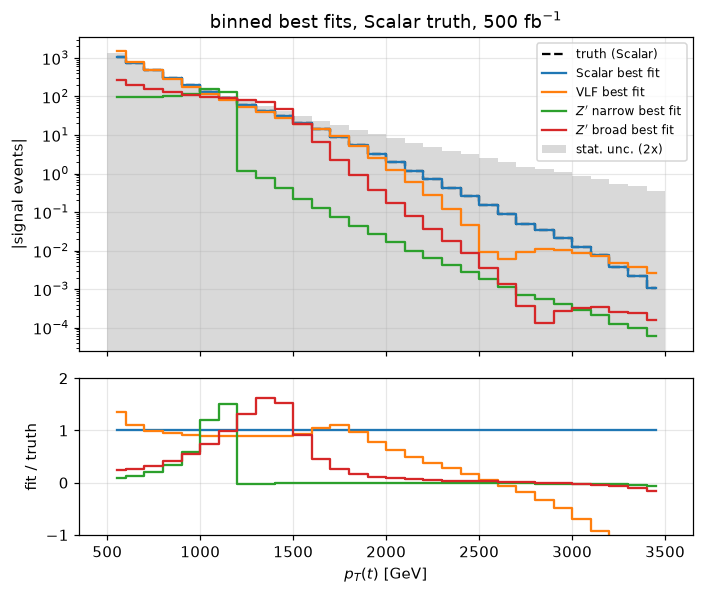

In [10]:
def plot_fig9(res, truth, title):
    # Fig. 9 analogue: BSM p_T distribution of the best fits, ratio to the truth
    cells = A.Cells(S, PT_BINS)
    nT = cells.counts(S.r_benchmark(truth) - 1) * A.FB * LUMI0
    ntot = cells.counts(S.r_benchmark(truth)) * A.FB * LUMI0
    xc = 0.5 * (PT_BINS[1:] + PT_BINS[:-1])
    fig, (a0, a1) = plt.subplots(2, 1, figsize=(6.5, 5.5), sharex=True, gridspec_kw=dict(height_ratios=[2, 1]))
    a0.bar(xc, 2 * np.sqrt(np.abs(ntot)), width=100, color="0.85", label="stat. unc. (2x)")
    a0.step(xc, np.abs(nT), where="mid", c="k", ls="--", label=f"truth ({LABEL[truth]})")
    for h in HYPS:
        f = res[truth]["fits"][h]
        n = cells.counts(A.r_of(S, f) - 1) * A.FB * LUMI0
        a0.step(xc, np.abs(n), where="mid", label=f"{LABEL[h]} best fit")
        with np.errstate(divide="ignore", invalid="ignore"):
            a1.step(xc, n / nT, where="mid")
    a0.set_yscale("log"); a0.set_ylabel("|signal events|"); a0.legend(fontsize=8); a0.set_title(title)
    a1.set_ylim(-1, 2); a1.set_xlabel(r"$p_T(t)$ [GeV]"); a1.set_ylabel("fit / truth"); plt.tight_layout()

plot_fig9(RB, "Scalar", "binned best fits, Scalar truth, 500 fb$^{-1}$")

## Unbinned analysis (Step A, Step B)

One cell per event: $\chi^2_H=2L\sum_j w_j[r_H-r_T+r_T\ln(r_T/r_H)]$ and $q_A=2L\sum_j w_j[r_0-r_1+r_1\ln(r_1/r_0)]$.

In [11]:
print("unbinned:"); RU = run_all(None)
for t in ["Scalar", "VLF", "Zp20"]:
    print(f"truth = {t}  (unbinned, L = {LUMI0:.0f} fb^-1)")
    display(fit_table(RU, t))

unbinned:


  4 truths done in 72s
truth = Scalar  (unbinned, L = 500 fb^-1)


,M,theta,chi2,M_paper,theta_paper,chi2_paper
hypothesis,,,,,,
Scalar,1500.0000,56.2500,-1.9241e-13,1510.2,57.7600,0.009
VLF,1748.3214,20.7705,1.3330e+00,1744.5,21.1600,0.850
Zp01,3300.0000,-0.0029,3.9127e+01,2500.1,-0.0056,23.300
Zp20,3206.7327,-0.0476,1.7077e+01,2882.0,-0.0474,10.500


truth = VLF  (unbinned, L = 500 fb^-1)


,M,theta,chi2,M_paper,theta_paper,chi2_paper
hypothesis,,,,,,
Scalar,1289.0940,37.7751,1.8115e+00,1247.0,34.8100,0.830
VLF,1500.0000,14.4400,-1.4927e-13,1505.3,14.4400,0.008
Zp01,3035.5314,-0.0030,3.7671e+01,2908.9,-0.0066,22.200
Zp20,3004.7657,-0.0446,1.3853e+01,2811.0,-0.0442,9.300


truth = Zp20  (unbinned, L = 500 fb^-1)


,M,theta,chi2,M_paper,theta_paper,chi2_paper
hypothesis,,,,,,
Scalar,1300.0,37.0429,2.2633e+01,1336.1,36.0000,10.30
VLF,1500.0,13.8581,2.0681e+01,1518.0,12.9600,11.20
Zp01,3000.0,-0.0040,4.8223e+01,2915.9,-0.0080,11.00
Zp20,3000.0,-0.0553,-1.3010e-13,3009.8,-0.0537,0.06


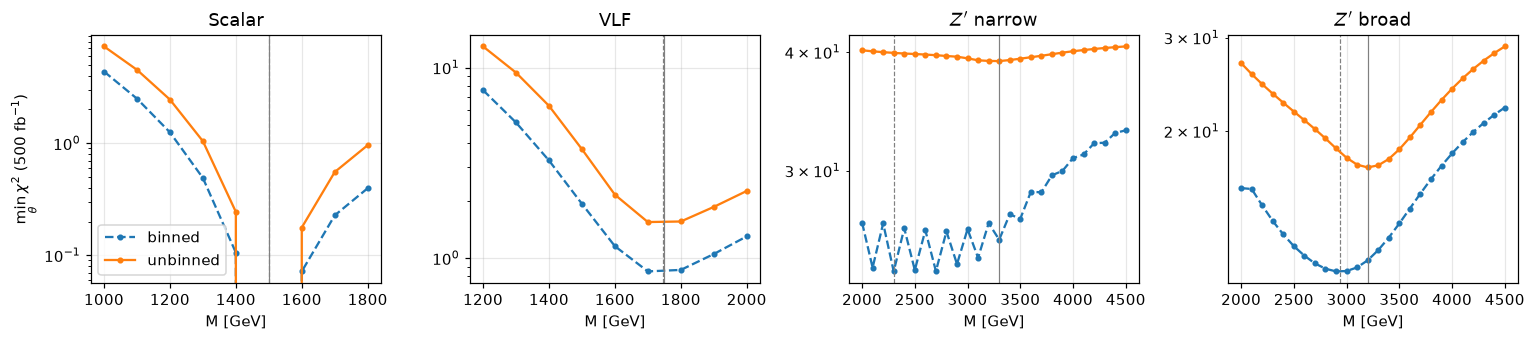

In [12]:
# Step-A profiles chi^2(M) (theta profiled), binned vs unbinned, Scalar truth
fig, axs = plt.subplots(1, 4, figsize=(14, 3.2))
for ax, h in zip(axs, HYPS):
    for res, lab, ls in ((RB, "binned", "--"), (RU, "unbinned", "-")):
        f = res["Scalar"]["fits"][h]
        ax.plot(f["grid"], f["profile"][:, 1], ls, marker=".", label=lab)
        ax.axvline(f["M"], ls=ls, c="0.5", lw=0.8)
    ax.set_title(LABEL[h]); ax.set_xlabel("M [GeV]"); ax.set_yscale("log")
axs[0].set_ylabel(r"$\min_\theta \chi^2$ (500 fb$^{-1}$)"); axs[0].legend(); plt.tight_layout()

## Binned vs unbinned

Without systematics $q_A\propto L$, so $Z_A(L)=Z_A(L_0)\sqrt{L/L_0}$ and the best fits do not depend on $L$.

In [13]:
def z_table(res, lumi):
    return pd.DataFrame({LABEL[t]: {LABEL[h]: z * np.sqrt(lumi / LUMI0) for h, z in res[t]["Z"].items()}
                         for t in res}).loc[[LABEL[h] for h in HYPS + ["SM"]]]

print("Z_A at 500 fb^-1  [rows: tested H0, columns: truth H1]")
display(pd.concat({"binned": z_table(RB, 500), "unbinned": z_table(RU, 500)}, axis=1))
print("Z_A at 3 ab^-1")
paper = pd.DataFrame({LABEL[t]: {LABEL[h]: PAPER_Z3000[h].get(t, np.nan) for h in HYPS} for t in TRUTHS})
display(pd.concat({"paper (Fig. 12)": paper, "binned": z_table(RB, 3000).loc[paper.index],
                   "unbinned": z_table(RU, 3000).loc[paper.index]}, axis=1))

Z_A at 500 fb^-1  [rows: tested H0, columns: truth H1]


binned                                unbinned          \
             Scalar     VLF $Z'$ broad $Z'$ narrow   Scalar     VLF   
Scalar          NaN  0.9255     3.2951      1.0879      NaN  1.3459   
VLF          0.8974     NaN     3.4418      1.0755   1.1546     NaN   
$Z'$ narrow  4.8467  4.7494     3.0296         NaN   6.2552  6.1377   
$Z'$ broad   3.2964  3.1821        NaN      0.7646   4.1325  3.7219   
SM           5.9760  5.9831     6.1873      1.3050   6.4153  6.4362   

                                    
            $Z'$ broad $Z'$ narrow  
Scalar          4.7574      3.7010  
VLF             4.5476      3.6305  
$Z'$ narrow     6.9443         NaN  
$Z'$ broad         NaN      3.4135  
SM              7.7196      3.8034

Z_A at 3 ab^-1


paper (Fig. 12)                                binned           \
                     Scalar   VLF $Z'$ broad $Z'$ narrow   Scalar      VLF   
Scalar                  NaN   2.2        7.8        12.5      NaN   2.2669   
VLF                     2.2   NaN        8.2        12.4   2.1981      NaN   
$Z'$ narrow            11.7  11.5        8.0         NaN  11.8719  11.6336   
$Z'$ broad              7.9   7.5        NaN         9.4   8.0745   7.7944   

                                   unbinned                                  
            $Z'$ broad $Z'$ narrow   Scalar      VLF $Z'$ broad $Z'$ narrow  
Scalar          8.0712      2.6648      NaN   3.2968    11.6532      9.0656  
VLF             8.4307      2.6345   2.8281      NaN    11.1394      8.8928  
$Z'$ narrow     7.4210         NaN  15.3220  15.0342    17.0099         NaN  
$Z'$ broad         NaN      1.8728  10.1225   9.1169        NaN      8.3613

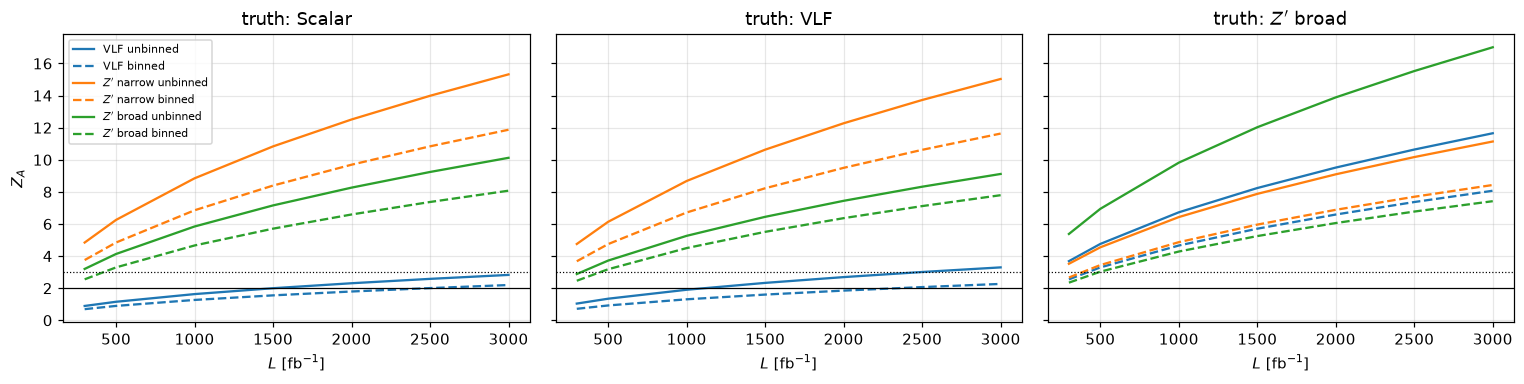

In [14]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for ax, t in zip(axs, ["Scalar", "VLF", "Zp20"]):
    for k, h in enumerate([h for h in HYPS if h != t]):
        c = f"C{k}"
        ax.plot(LUMIS, RU[t]["Z"][h] * np.sqrt(LUMIS / LUMI0), c=c, label=f"{LABEL[h]} unbinned")
        ax.plot(LUMIS, RB[t]["Z"][h] * np.sqrt(LUMIS / LUMI0), c=c, ls="--", label=f"{LABEL[h]} binned")
    ax.axhline(2, c="k", lw=0.8); ax.axhline(3, c="k", lw=0.8, ls=":")
    ax.set_title(f"truth: {LABEL[t]}"); ax.set_xlabel(r"$L$ [fb$^{-1}$]")
axs[0].set_ylabel(r"$Z_A$"); axs[0].legend(fontsize=7); plt.tight_layout()

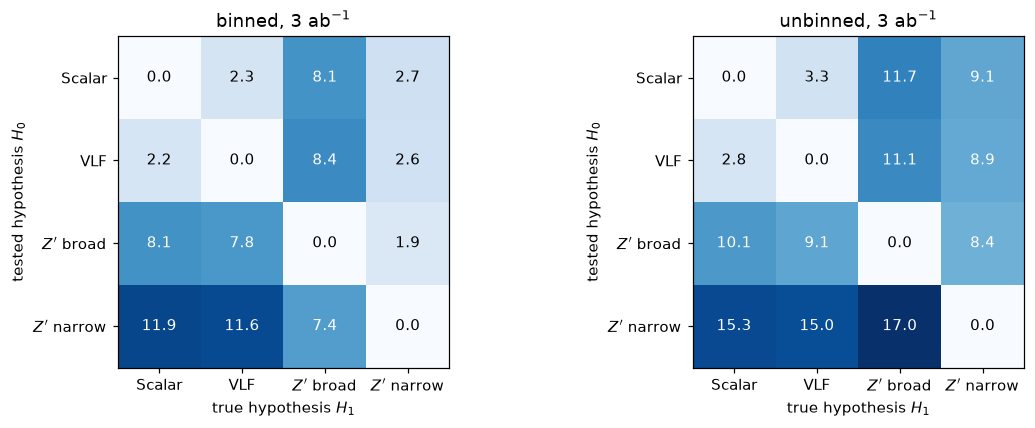

In [15]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for ax, res, title in ((axs[0], RB, "binned"), (axs[1], RU, "unbinned")):
    M = np.array([[0.0 if h == t else res[t]["Z"][h] * np.sqrt(3000 / LUMI0) for t in TRUTHS] for h in TRUTHS])
    im = ax.imshow(M, cmap="Blues", vmin=0, vmax=max(13, M.max()))
    for i in range(len(TRUTHS)):
        for j in range(len(TRUTHS)):
            ax.text(j, i, f"{M[i, j]:.1f}", ha="center", va="center", color="w" if M[i, j] > 7 else "k")
    ax.set_xticks(range(4), [LABEL[t] for t in TRUTHS]); ax.set_yticks(range(4), [LABEL[t] for t in TRUTHS])
    ax.set_xlabel("true hypothesis $H_1$"); ax.set_ylabel("tested hypothesis $H_0$"); ax.grid(False)
    ax.set_title(f"{title}, 3 ab$^{{-1}}$")
plt.tight_layout()

### Consistency checks

1. **Log-sum inequality.** For the *same* pair $(r_0, r_1)$, the unbinned $q_A$ must be at least the binned one (exact for positive weights, which holds in the nominal $|f_af_b|$ convention).
2. **Step-B Asimov data.** $r_1$ (truth model at its own best fit) vs the benchmark $r_T$: identical up to the truth's best-fit deviance.
3. **Mixed analysis.** Binned Step-A fits with unbinned $q_A$, which separates the gain coming from the fit from the gain coming from the test.

In [16]:
# the log-sum inequality needs binned and unbinned on the SAME sample (PDF set)
RBs = RB if PDF == cfg.PDF_GEN else run_all(PT_BINS)
cb, cu = A.Cells(S, PT_BINS), A.Cells(S, None)
rows = []
for t in ["Scalar", "VLF", "Zp20"]:
    r1u = RU[t]["r1"]; rT = S.r_benchmark(t)
    for h in [h for h in HYPS + ["SM"] if h != cfg.BENCHMARKS[t]["model"]]:
        r0 = A.r_of(S, RBs[t]["fits"][h])                         # binned best fit of H0
        r1b = RBs[t]["r1"]
        qb, qu = A.q_asimov(cb, r0, r1b, LUMI0), A.q_asimov(cu, r0, r1b, LUMI0)
        qT = A.q_asimov(cu, A.r_of(S, RU[t]["fits"][h]), rT, LUMI0)
        rows.append(dict(truth=t, H0=h, Z_binned=np.sqrt(qb), Z_unbinned_same_fits=np.sqrt(qu),
                         inequality_ok=qu >= qb * (1 - 1e-6), Z_unbinned=RU[t]["Z"][h], Z_unbinned_rT=np.sqrt(qT)))
pd.DataFrame(rows)

  4 truths done in 6s


,truth,H0,Z_binned,Z_unbinned_same_fits,inequality_ok,Z_unbinned,Z_unbinned_rT
0,Scalar,VLF,0.8964,1.1546,True,1.1546,1.1546
1,Scalar,Zp01,4.9183,11.6276,True,6.2552,6.2552
2,Scalar,Zp20,3.3762,4.5024,True,4.1325,4.1325
3,Scalar,SM,6.0647,6.4153,True,6.4153,6.4153
4,VLF,Scalar,0.9180,1.3808,True,1.3459,1.3459
5,VLF,Zp01,4.8324,10.4931,True,6.1377,6.1377
6,VLF,Zp20,3.2478,4.1714,True,3.7219,3.7219
7,VLF,SM,6.0484,6.4362,True,6.4362,6.4362
8,Zp20,Scalar,3.4285,4.7775,True,4.7574,4.7574
9,Zp20,VLF,3.5835,4.5944,True,4.5476,4.5476


##  Monte Carlo precision and robustness

* $N_{\rm eff}=(\sum w)^2/\sum w^2$ and a Poisson bootstrap of the events at fixed best fits (the spread of $Z_A$ from the finite MC sample).
* PDF convention: the nominal analysis sets every PDF to zero where it is negative, $f\to\max(f,0)$ (a 100% uncertainty on the NLO fit at large $x$; `ExtendedMEM.tex`, Eq. lumi), converting each generator weight with $D_c/D^{\rm signed}_c$ of its own integration channel ($gg$, $q\bar q$ with the quark from beam 1, or from beam 2: each generated event comes from one oriented channel); events whose weight becomes zero are removed. Variation: MadEvent's LO convention $|f_af_b|$ per ordered pair, with the same conversion. The signed products the generator sampled are not a usable variation either: where the negative large-$x$ gluon cancels the $q\bar q$ term, $D_{\rm SM}\to0$ and $r_H$ blows up (a PDF artefact; on the full sample the deviance becomes infinite).
* a large-$x$ cut, $\max(x_1,x_2)<0.4$, which removes the region where the NNPDF2.3 densities are negative and poorly constrained.

In [17]:
print(f"N = {len(S.w)},  N_eff = {S.n_eff:.0f},  N_eff(pT > 1.2 TeV) = "
      f"{S.w[S.pt > 1200].sum()**2 / np.sum(S.w[S.pt > 1200]**2):.0f}")
rows = []
for t in ["Scalar", "VLF", "Zp20"]:
    for h in [h for h in HYPS if h != cfg.BENCHMARKS[t]["model"]]:
        qb = A.bootstrap_q(cu, A.r_of(S, RU[t]["fits"][h]), RU[t]["r1"], LUMI0, nboot=100)
        zb = np.sqrt(np.clip(qb, 0, None))
        rows.append(dict(truth=t, H0=h, Z=RU[t]["Z"][h], Z_boot_mean=zb.mean(), Z_boot_std=zb.std()))
pd.DataFrame(rows)

N = 2405721,  N_eff = 520841,  N_eff(pT > 1.2 TeV) = 126425


,truth,H0,Z,Z_boot_mean,Z_boot_std
0,Scalar,VLF,1.1546,1.1547,0.0012
1,Scalar,Zp01,6.2552,6.2552,0.0035
2,Scalar,Zp20,4.1325,4.1329,0.0023
3,VLF,Scalar,1.3459,1.3460,0.0014
4,VLF,Zp01,6.1377,6.1375,0.0034
5,VLF,Zp20,3.7219,3.7220,0.0017
6,Zp20,Scalar,4.7574,4.7570,0.0055
7,Zp20,VLF,4.5476,4.5472,0.0043
8,Zp20,Zp01,6.9443,6.9435,0.0081


In [18]:
variants = {"nominal": S, "|f_a f_b| (MadEvent LO)": A.Sample(EVENTS, pdf=PDF, flux_mode="abs"),
            "max(x1,x2) < 0.4": A.Sample(EVENTS, pdf=PDF, xcut=0.4)}
tabs = {}
for name, smp in variants.items():
    if name == "nominal":
        res = RU
    else:
        print(name); res = run_all(None, sample=smp, truths=["Scalar", "VLF", "Zp20"])
    tabs[name] = z_table(res, 3000)[[LABEL[t] for t in ["Scalar", "VLF", "Zp20"]]]
print("unbinned Z_A at 3 ab^-1 (fits redone in each variant)")
pd.concat(tabs, axis=1)

|f_a f_b| (MadEvent LO)


  3 truths done in 57s
max(x1,x2) < 0.4


  3 truths done in 46s
unbinned Z_A at 3 ab^-1 (fits redone in each variant)


nominal                     |f_a f_b| (MadEvent LO)           \
              Scalar      VLF $Z'$ broad                  Scalar      VLF   
Scalar           NaN   3.2968    11.6532                     NaN   3.2968   
VLF           2.8281      NaN    11.1394                  2.8281      NaN   
$Z'$ narrow  15.3220  15.0342    17.0099                 15.3220  15.0342   
$Z'$ broad   10.1225   9.1169        NaN                 10.1225   9.1169   
SM           15.7142  15.7655    18.9090                 15.7142  15.7655   

                       max(x1,x2) < 0.4                      
            $Z'$ broad           Scalar      VLF $Z'$ broad  
Scalar         11.6532              NaN   2.6112     9.7499  
VLF            11.1394           2.2914      NaN     9.5802  
$Z'$ narrow    17.0099          12.9139  13.1228    13.8636  
$Z'$ broad         NaN           8.6815   8.3649        NaN  
SM             18.9090          13.2278  13.7034    15.4161